# 共享单车分析（2024-01）：数据、站点潮汐与预测评估

本 Notebook 复现课程成果包中的关键统计与图表，**不重新训练模型，也不重新评估测试集**。

- 数据：`data/clean/rides.csv`（238,699 行，2024-01-01 至 2024-02-01）
- 已确认模型：`hgb_full`（`results/real_run_01`，测试期只评估过一次）
- 候选实验：`opt_v020_001`、`opt_v021_001`（**只有验证成绩**）
- 本 Notebook 依赖原工程数据与冻结结果，不能脱离工程独立运行；所有路径由 `handoff_config.json` 统一配置。

## 1. 环境与数据加载

配置给出工程根目录、数据文件与实验目录；加载后先核对行数与版本。

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

sys.path.insert(0, str(Path.cwd()))
from handoff import core, figures

cfg = core.load_config(Path.cwd() / "handoff_config.json")
data = core.load_data(cfg)
pd.set_option("display.width", 180)
print("project root:", cfg["_root"])
print("rides:", len(data.rides))
print("coverage:", len(data.coverage))
print("panel:", len(data.panel), "rows;", data.panel.station_id.nunique(), "stations")

project root: D:\新建文件夹 (4)\bike_analysis_project
rides: 238699
coverage: 985
panel: 14880 rows; 20 stations


## 2. 数据与口径

三种口径不能互换：全量订单（238,699）、有站点端点的子集（201,574 / 199,070）、建模面板（20 站 × 744 小时）。

In [2]:
scope = core.scope_counts(data)
display(scope)
versions = pd.DataFrame([data.versions]).T
versions.columns = ["value"]
display(versions)

,scope,rows,share,definition
0,全量订单,238699,1.000000,分析窗口内按 started_at 统计的全部有效骑行
1,有起点的端点,201574,0.844469,start_station_id 非空，可计入站点借出
2,有终点的端点（全量）,199070,0.833979,end_station_id 非空；包含 2 月 1 日到达的 35 条跨月订单
3,到达在窗口内的终点端点,199053,0.833908,end_station_id 非空且 ended_at < 2024-02-01，可计入站点归还
4,起终点都有,183870,0.770301,可同时计入借出与归还
5,建模面板（20 站 × 744 h）,14880,NaN,仅覆盖选定 20 站的站点小时面板，与全量订单口径不同


,value
rides_sha256,02f37c8f6788d0a105fadd3868b73ae11f1d39af30b9ed...
rides_rows,238699
coverage_rows,985
coverage_assumed_rows,985
stations_rows,761
panel_rows,14880
panel_stations,20
prediction_rows,73920
window_start,2024-01-01 00:00:00
window_end,2024-02-01 00:00:00


## 3. 清洗结果审计

保留 238,699 条、拒绝 135 条（44 条负时长、91 条零时长）。站点缺失与长时长记录被保留并打标，不删除。

In [3]:
cleaning = data.cleaning
audit = pd.DataFrame([
    {"item": "raw_rows", "value": cleaning["raw_rows"]},
    {"item": "retained_rows", "value": cleaning["retained_rows"]},
    {"item": "rejected_unique_rows", "value": cleaning["rejected_unique_rows"]},
    {"item": "exact_duplicates_removed", "value": cleaning["exact_duplicates_removed"]},
    {"item": "missing_start_station", "value": cleaning["quality_flag_counts"]["missing_start_station"]},
    {"item": "missing_end_station", "value": cleaning["quality_flag_counts"]["missing_end_station"]},
    {"item": "long_duration_ge_180min", "value": cleaning["quality_flag_counts"]["long_duration_reviewed"]},
    {"item": "duration_at_24h_cap", "value": cleaning["quality_flag_counts"]["duration_at_24h_cap"]},
])
display(audit)
display(pd.Series(cleaning["duration_summary_retained"]).to_frame("value"))
rejected = pd.read_csv(core.p(cfg, "data/clean/rejected_rows.csv"), dtype=str)
display(rejected.rejection_reason.value_counts().rename("rows").to_frame())

,item,value
0,raw_rows,238834
1,retained_rows,238699
2,rejected_unique_rows,135
3,exact_duplicates_removed,0
4,missing_start_station,37125
5,missing_end_station,39629
6,long_duration_ge_180min,797
7,duration_at_24h_cap,228


,value
count,238699.0000
min,0.0167
p50,8.7667
p90,23.7333
p95,34.2667
p99,81.8837
p999,1393.6701
max,1499.9500
mean,14.7790
ge_180_min,797.0000


,rows
rejection_reason,
end_not_after_start,135


## 4. 出行规律

工作日双峰（08:00、17:00），周末单峰（14–16 时）。先看每日总量，再看工作日/周末的日均小时曲线。

,date,rides
0,2024-01-01,4898
1,2024-01-02,7806
2,2024-01-03,9143


,date,rides
28,2024-01-29,9625
29,2024-01-30,10478
30,2024-01-31,10566


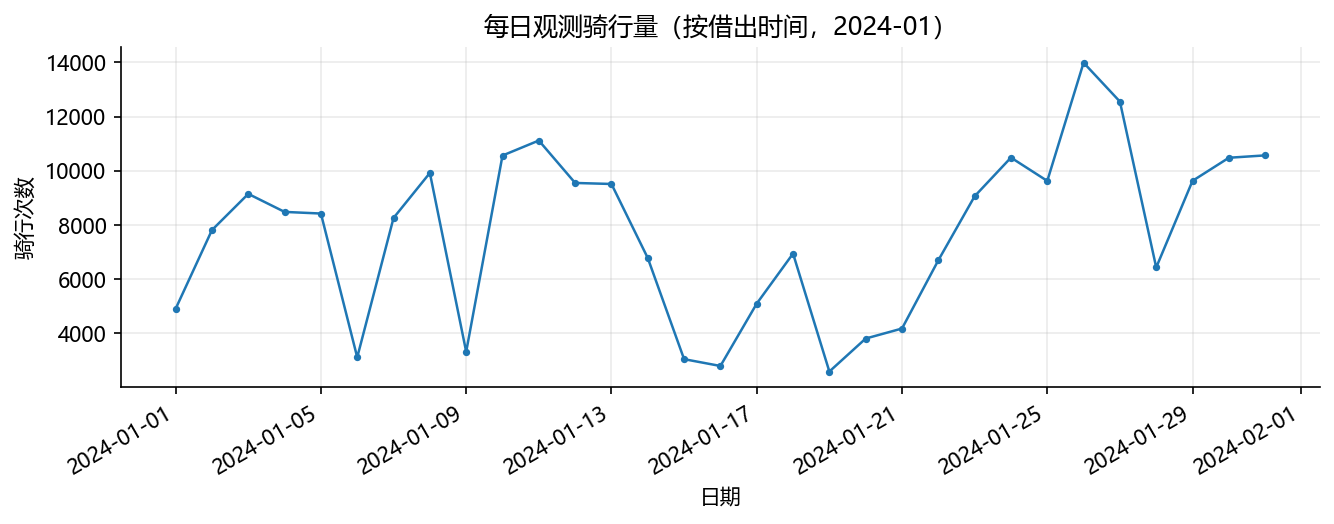

In [4]:
daily = core.daily_series(data)
display(daily.head(3))
display(daily.tail(3))
figures.fig_daily(data, Path("figures"))
display(Image(filename="figures/fig01_daily_trips.png"))

,hour,rides_all,weekday_mean,weekend_mean
0,0,2461,58.5,139.4
1,1,1594,34.1,101.1
2,2,1042,23.7,62.2
3,3,469,10.7,28.0
4,4,551,16.4,21.6
5,5,1477,57.0,20.9
6,6,4597,181.9,51.8
7,7,10388,418.0,96.6
8,8,18196,717.4,211.9
9,9,12860,443.6,332.2


weekday days: 23 weekend days: 8


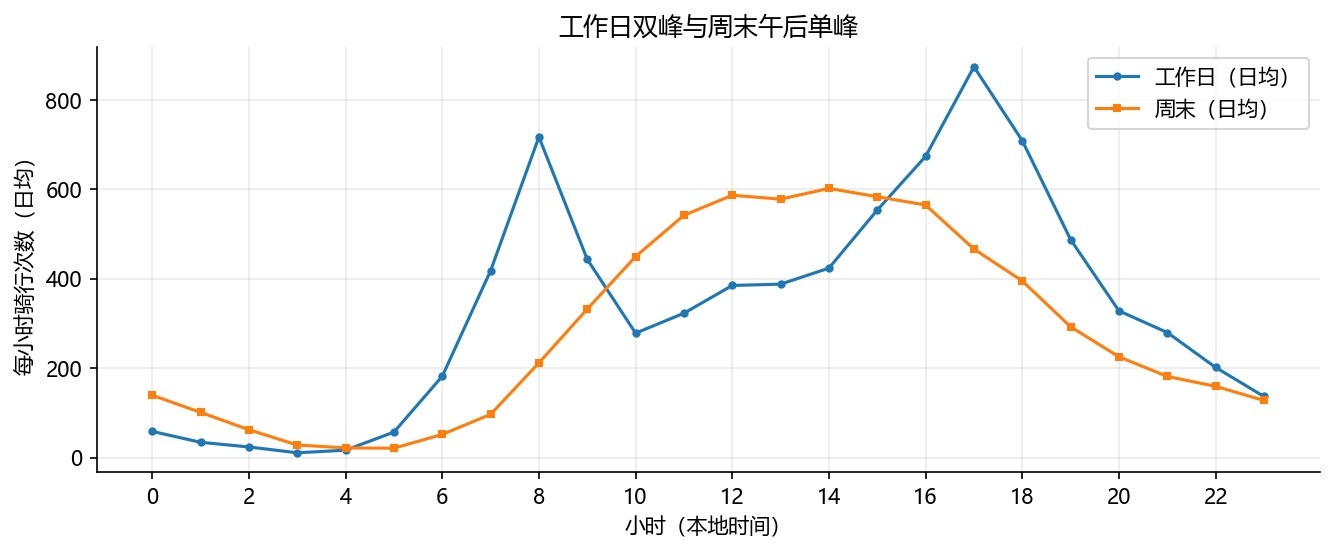

In [5]:
hourly = core.hourly_tables(data)
display(hourly["table"].round(1))
print("weekday days:", hourly["weekday_days"], "weekend days:", hourly["weekend_days"])
figures.fig_hourly(data, Path("figures"))
display(Image(filename="figures/fig02_hourly_profile.png"))

hour,6,7,8,17,18
weekday,,,,,
0,144.2,315.0,536.4,680.8,568.6
1,204.0,436.4,695.8,759.4,610.4
2,204.8,507.6,912.6,1060.6,880.2
3,200.0,478.5,886.5,1015.0,827.5
4,154.5,351.5,557.8,887.0,676.0
5,67.2,128.5,247.0,491.0,396.0
6,36.2,64.8,176.8,442.2,394.5


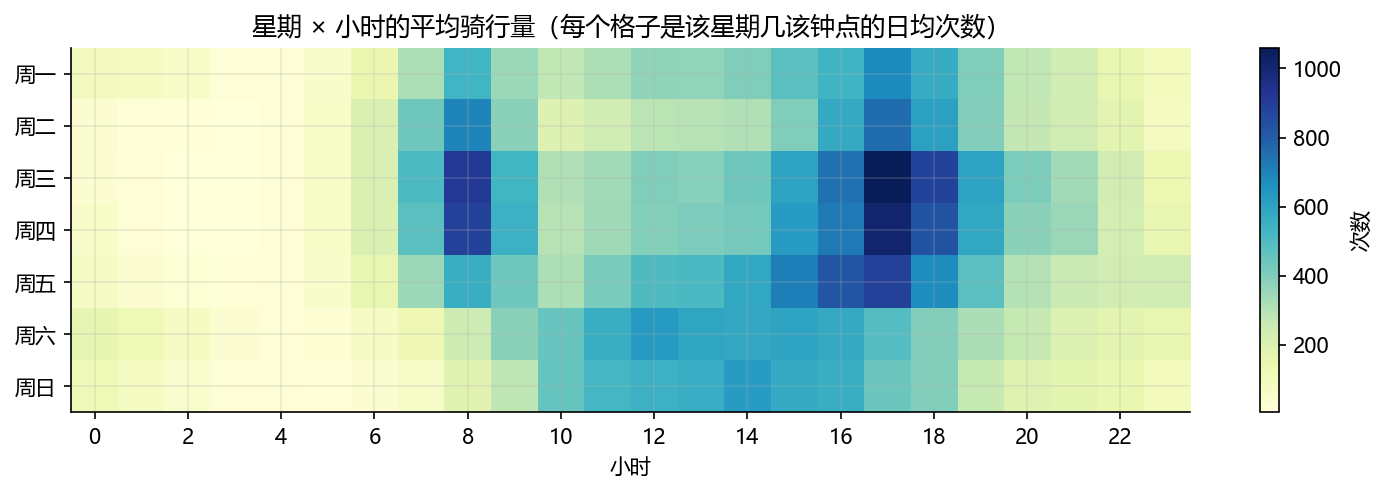

In [6]:
matrix = core.weekday_hour_matrix(data)
display(matrix.round(1).loc[:, [6, 7, 8, 17, 18]])
figures.fig_heatmap(data, Path("figures"))
display(Image(filename="figures/fig03_weekday_hour_heatmap.png"))

会员占 74.1%，电动车占 51.1%。casual 与 classic 的骑行时长中位数更高。

,member_type,rides,median_duration_min,mean_duration_min,p90_duration_min,share
0,casual,61738,10.550,21.106,33.683,0.259
1,member,176961,8.217,12.572,21.133,0.741


,bike_type,rides,median_duration_min,mean_duration_min,p90_duration_min,share
0,classic,116663,9.083,18.043,25.850,0.489
1,electric,122036,8.467,11.659,21.933,0.511


bike_type,member_type,classic,electric
0,casual,27126,34612
1,member,89537,87424


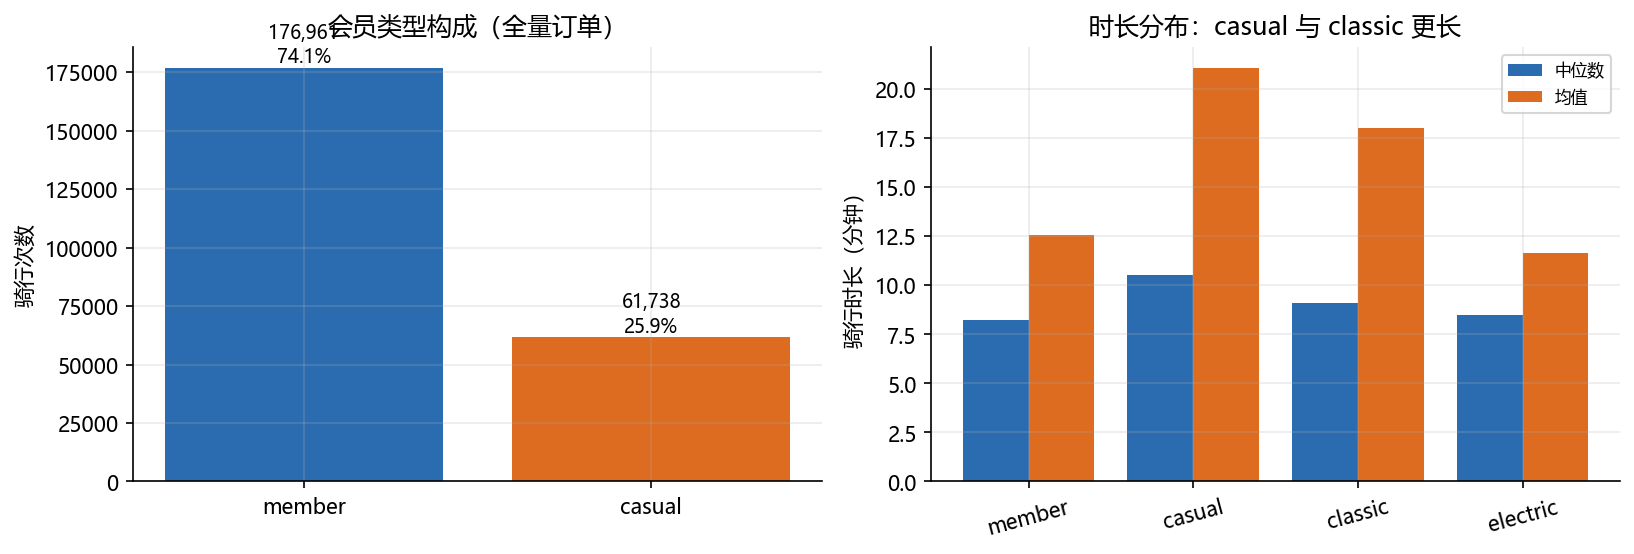

In [7]:
mb = core.member_bike_tables(data)
display(mb["member"].round(3))
display(mb["bike"].round(3))
display(mb["cross"])
figures.fig_member_bike(data, Path("figures"))
display(Image(filename="figures/fig04_member_bike.png"))

## 5. 站点潮汐与失衡

净流量 = 借出 − 归还，是**记录差**，不是真实缺车量。站点容量与库存未知。

In [8]:
stations = core.station_totals(data)
tide = core.tide_table(data)
display(stations.head(8)[["station_id", "station_name", "departures", "arrivals", "net", "events"]])

,station_id,station_name,departures,arrivals,net,events
0,31623,Columbus Circle / Union Station,2998.0,2957.0,41.0,5955.0
1,31229,New Hampshire Ave & T St NW,2552.0,2541.0,11.0,5093.0
2,31201,15th & P St NW,2049.0,2045.0,4.0,4094.0
3,31101,14th & V St NW,1932.0,1893.0,39.0,3825.0
4,31600,5th & K St NW,1843.0,1869.0,-26.0,3712.0
5,31613,Eastern Market Metro / Pennsylvania Ave & 8th ...,1843.0,1852.0,-9.0,3695.0
6,31603,1st & M St NE,1749.0,1751.0,-2.0,3500.0
7,31627,M St & Delaware Ave NE,1757.0,1738.0,19.0,3495.0


In [9]:
top_events = set(tide.nlargest(20, "events").station_id)
top_net = set(tide.nlargest(20, "net").station_id) | set(tide.nsmallest(20, "net").station_id)
print("事件量前20 与 |净流量| 前20 的重合站点数:", len(top_events & top_net))
print("Spearman(事件量, |净流量|):", round(tide.events.corr(tide.net.abs(), method="spearman"), 3))
display(tide.nlargest(5, "net")[["station_id", "net", "events"]])
display(tide.nsmallest(5, "net")[["station_id", "net", "events"]])

事件量前20 与 |净流量| 前20 的重合站点数: 3


Spearman(事件量, |净流量|): 0.666


,station_id,net,events
44,31602,449.0,1939.0
64,31131,404.0,1612.0
35,31102,365.0,2085.0
86,31136,350.0,1466.0
95,31115,330.0,1392.0


,station_id,net,events
168,31293,-228.0,916.0
53,31230,-217.0,1793.0
24,31228,-211.0,2301.0
132,31215,-197.0,1155.0
52,31233,-175.0,1803.0


active stations: 355
reversal stations: 302 share: 0.851
corr(am_net, pm_net): -0.876


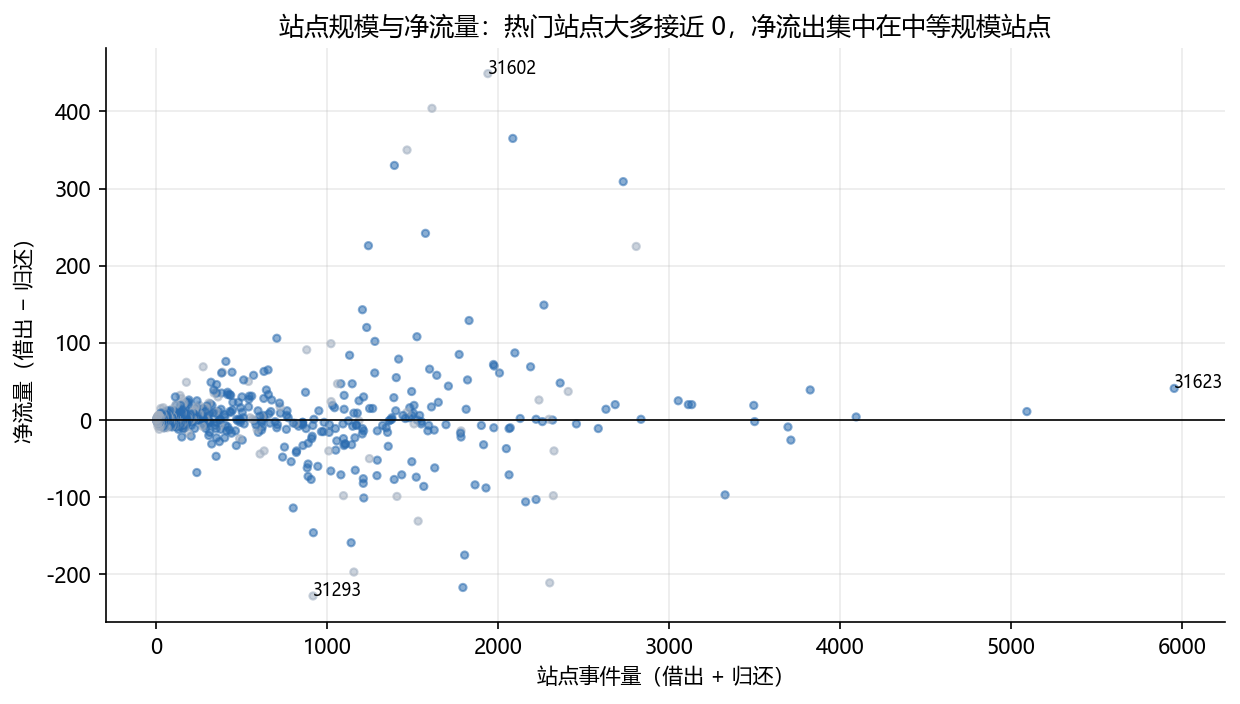

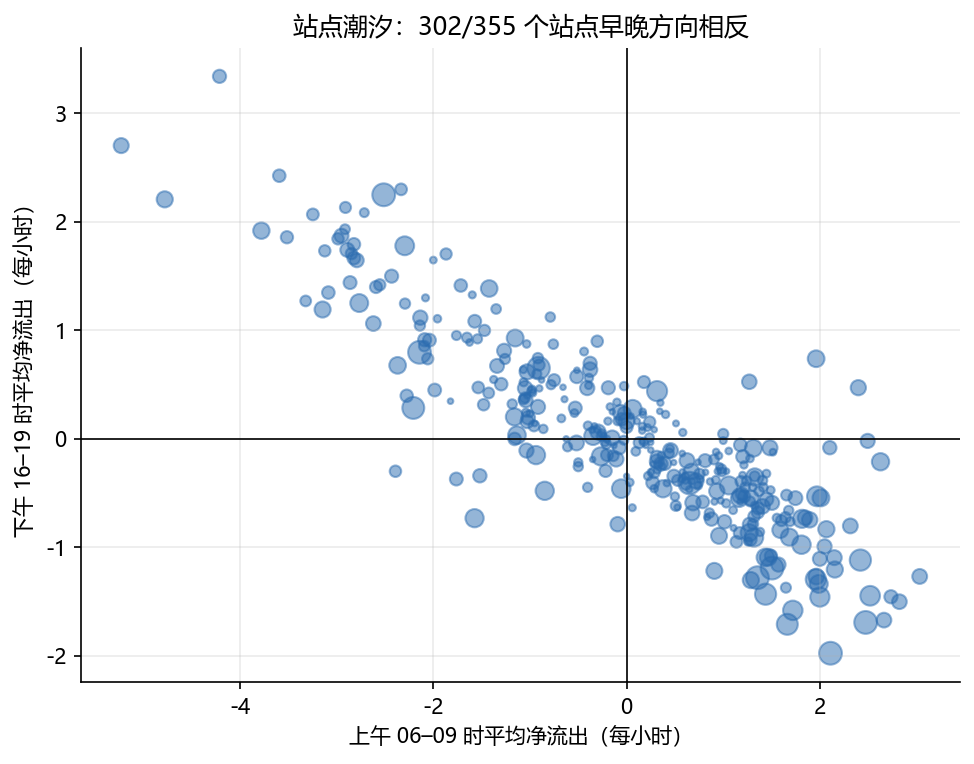

In [10]:
big = tide[tide.events >= 200]
print("active stations:", len(big))
print("reversal stations:", int(big.reversal.sum()), "share:", round(big.reversal.mean(), 3))
print("corr(am_net, pm_net):", round(big.am_net.corr(big.pm_net), 3))
figures.fig_station_scatter(data, tide, Path("figures"))
display(Image(filename="figures/fig05_station_scatter.png"))
figures.fig_tide(data, tide, Path("figures"))
display(Image(filename="figures/fig06_tide_scatter.png"))

代表站点按固定规则选取：最大事件量、最大净流出、最大净流入、最大潮汐振幅（高流量）、中等规模且净流量接近 0 的对照站。

,station_id,reason
0,31623,全网事件量最高，用于观察“热门但净流量接近 0”
1,31602,全网净流出最高（借出显著多于归还）
2,31293,全网净流入最高（归还显著多于借出）
3,31277,潮汐振幅大且发生在高流量站点，用于观察早晚方向反转
4,31291,中等规模、净流量接近 0，作为对照站点


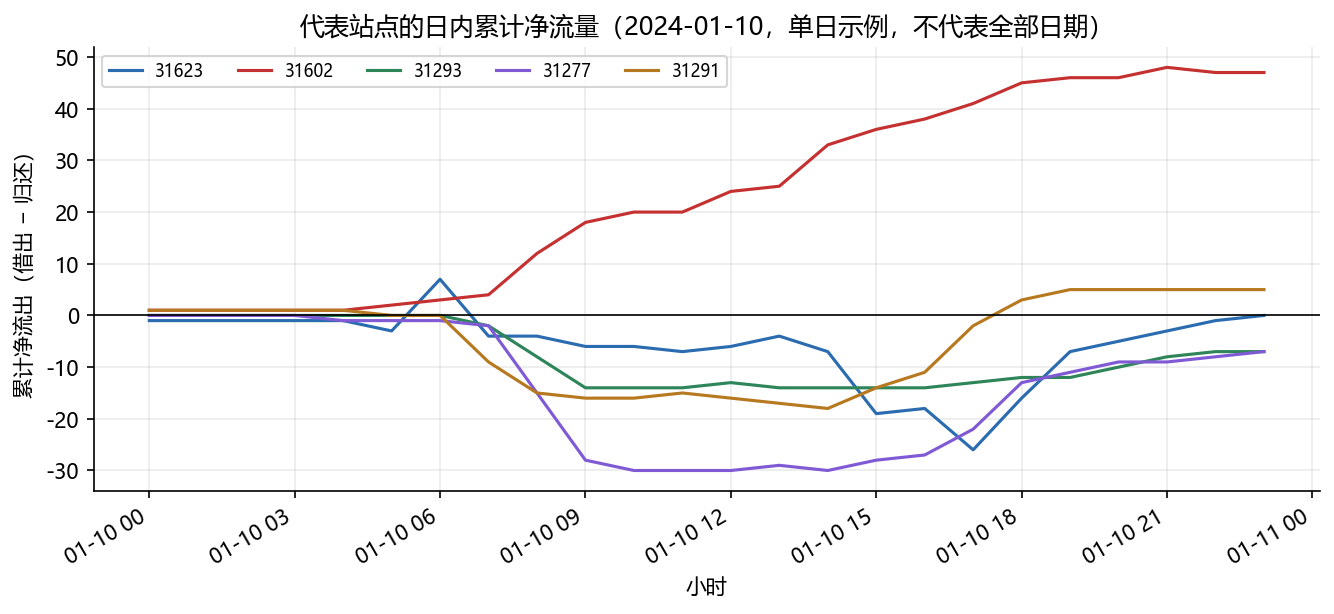

In [11]:
reps = core.representative_stations(data, tide)
display(pd.DataFrame(reps))
figures.fig_cumulative(data, reps, cfg["representative_day"], Path("figures"))
display(Image(filename="figures/fig07_representative_cumulative.png"))

## 6. 预测评估（冻结结果复核）

模型与划分都已在既有实验结果中确定：验证集选模，测试集只评估一次。这里只读取 `predictions.csv` 重新计算指标，不做训练。

,target,model,n,mae,rmse,bias,peak_mae,peak_underprediction_rate,interval_coverage,improvement_vs_previous_day
12,arrivals,hgb_calendar,3360,1.6546,2.7140,-0.9804,4.3294,0.9495,NaN,0.2003
13,arrivals,hgb_full,3360,1.4801,2.2738,-0.2150,3.0791,0.8245,0.9161,0.2846
14,arrivals,hgb_own_history,3360,1.4890,2.3062,-0.2775,3.1506,0.8231,NaN,0.2804
15,arrivals,historical_mean,3360,1.7214,2.8199,-0.9791,4.2877,0.8976,NaN,0.1680
16,arrivals,previous_day,3360,2.0690,3.2311,0.0107,3.8497,0.7021,NaN,0.0000
17,departures,hgb_calendar,3360,1.6932,2.6903,-1.0326,4.1452,0.9822,NaN,0.2059
18,departures,hgb_full,3360,1.4685,2.2184,-0.2886,2.8788,0.8514,0.9134,0.3113
19,departures,hgb_own_history,3360,1.5463,2.3394,-0.3132,3.0668,0.8514,NaN,0.2748
20,departures,historical_mean,3360,1.7744,2.8007,-1.0315,4.1272,0.9180,NaN,0.1678
21,departures,previous_day,3360,2.1321,3.2186,-0.0125,3.7099,0.6873,NaN,0.0000


,target,model,n,mae,rmse,bias
22,arrivals,hgb_calendar,2880,1.5436,2.3950,0.2302
23,arrivals,hgb_full,2880,1.1947,1.8796,-0.0710
24,arrivals,hgb_own_history,2880,1.2196,1.9047,-0.0412
25,arrivals,historical_mean,2880,1.6793,2.7412,0.2248
26,arrivals,previous_day,2880,1.4361,2.3784,-0.1514
27,departures,hgb_calendar,2880,1.5658,2.3565,0.2452
28,departures,hgb_full,2880,1.1648,1.7786,-0.0603
29,departures,hgb_own_history,2880,1.2645,1.9463,-0.0649
30,departures,historical_mean,2880,1.7500,2.7680,0.2354
31,departures,previous_day,2880,1.4715,2.3525,-0.1472


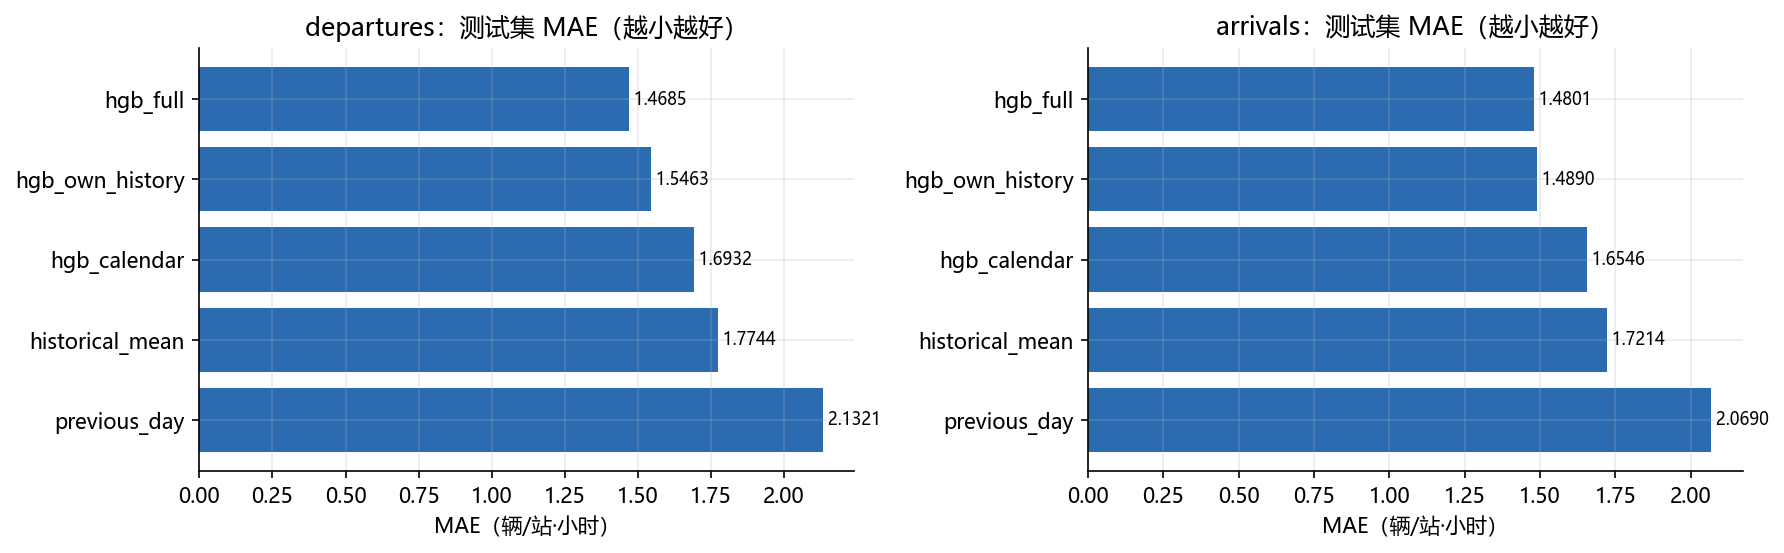

In [12]:
metrics = core.prediction_metrics(data)
test = metrics[metrics.split == "test"]
display(test[["target", "model", "n", "mae", "rmse", "bias", "peak_mae",
              "peak_underprediction_rate", "interval_coverage", "improvement_vs_previous_day"]].round(4))
validation = metrics[metrics.split == "validation"]
display(validation[["target", "model", "n", "mae", "rmse", "bias"]].round(4))
figures.fig_prediction_models(data, metrics, Path("figures"))
display(Image(filename="figures/fig08_prediction_models.png"))

,hour,mae,bias,rmse,n
0,0,0.648,-0.124,1.053,280
1,1,0.436,-0.034,0.806,280
2,2,0.314,-0.002,0.587,280
3,3,0.193,0.015,0.330,280
4,4,0.208,0.016,0.355,280
5,5,0.424,-0.090,0.629,280
6,6,1.000,0.034,1.608,280
7,7,1.601,-0.252,2.268,280
8,8,2.142,-0.549,3.108,280
9,9,1.768,-0.236,2.323,280


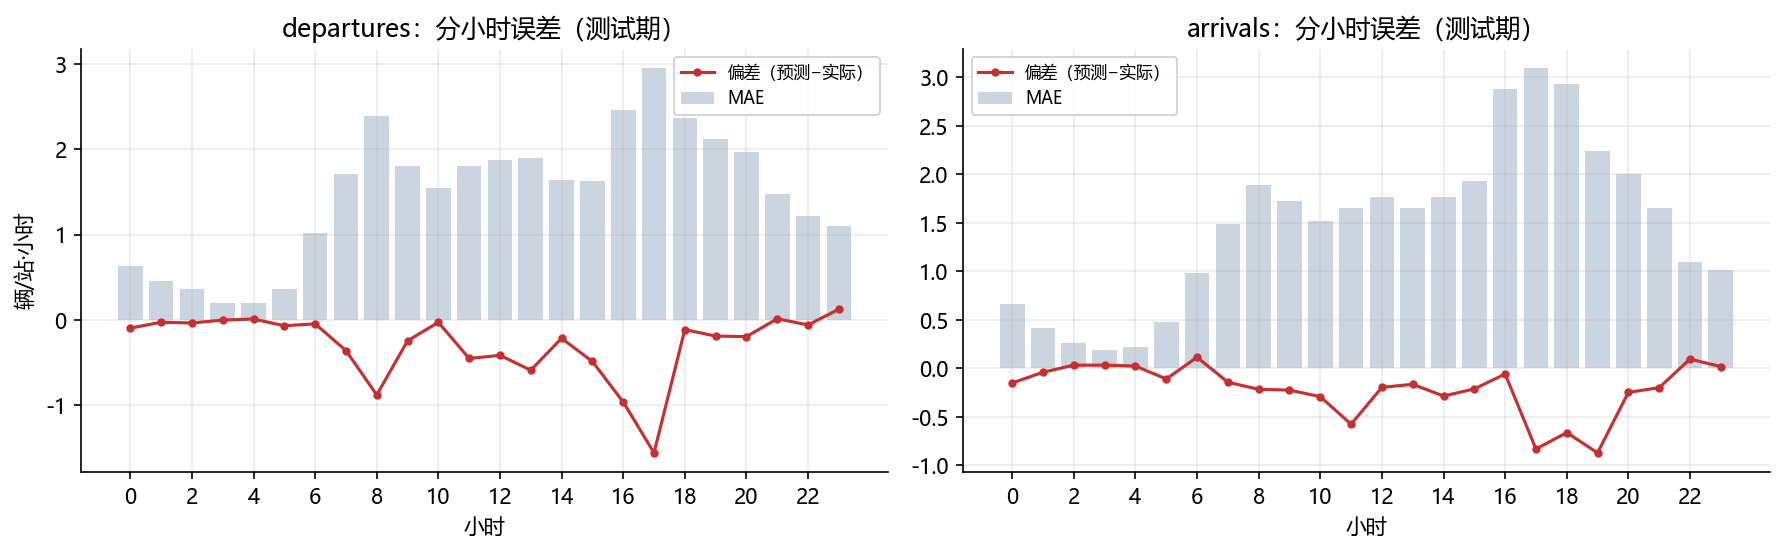

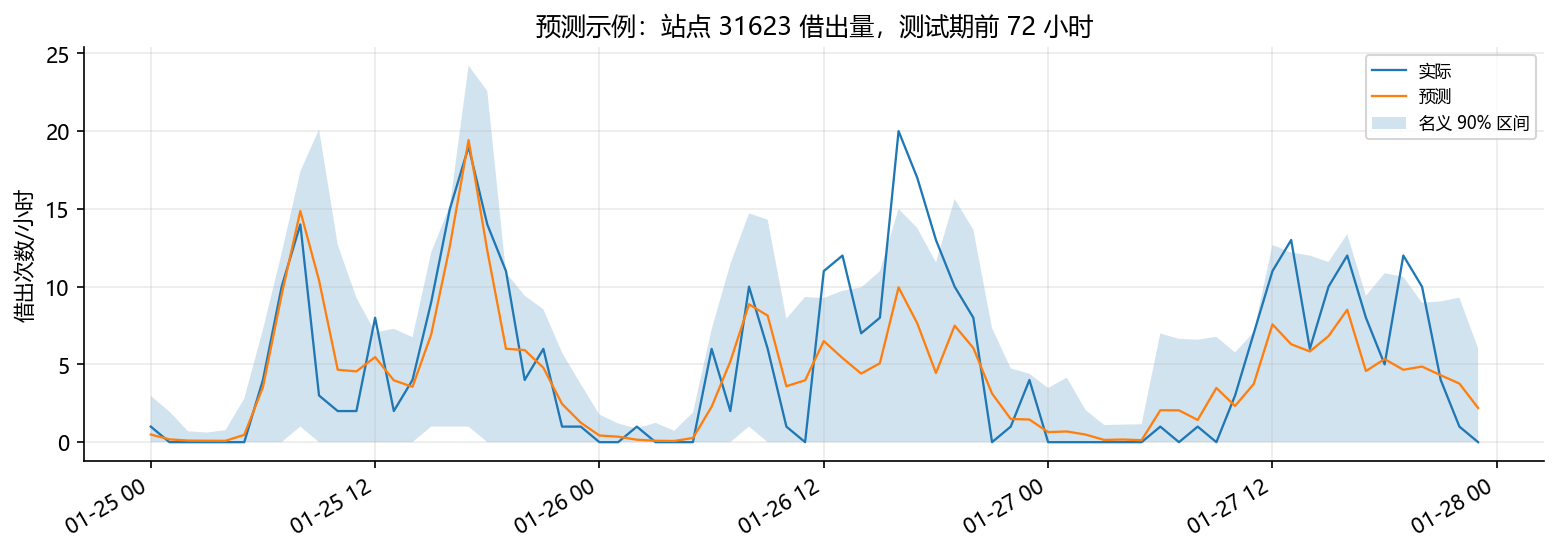

In [13]:
by_hour = core.prediction_hourly(data, "hgb_full", "test")
display(by_hour.round(3))
figures.fig_prediction_hourly(data, Path("figures"))
display(Image(filename="figures/fig09_prediction_hourly.png"))
figures.fig_prediction_example(data, "31623", Path("figures"))
display(Image(filename="figures/fig11_prediction_example.png"))

## 7. 优化实验总结（仅验证成绩）

两轮实验共 13 个新候选（v0.2.0 五个、v0.2.1 八个），只有 v0.2.1 的 `reg_leaf15_min30` 通过归还目标的预设门槛。
**候选没有任何测试成绩**，下表与 JSON 中的 `test_mae` 均为空。

,run_id,label,dir,candidates,model_entries,status,chosen,baseline_kept_for
0,opt_v020_001,v0.2.0 六条目（基线+5 变体）,experiments/opt_v020_001,5,6,validation_only,"{'departures': 'hgb_full', 'arrivals': 'hgb_fu...","[departures, arrivals]"
1,opt_v021_001,v0.2.1 九条目（基线+8 候选）,experiments/opt_v021_001,8,9,validation_only,"{'departures': 'hgb_full', 'arrivals': 'reg_le...",[departures]


opt_v020_001


,target,model,mae,paired_ci_low,paired_ci_high
0,arrivals,adaptive_longer,1.2268,0.0011,0.0680
1,arrivals,adaptive_mae,1.1877,-0.0864,0.0766
2,arrivals,adaptive_poisson,1.2031,-0.0223,0.0428
3,arrivals,adaptive_recent,1.2012,-0.0392,0.0530
4,arrivals,blend_mean_median,1.1821,-0.0578,0.0457
5,arrivals,hgb_full,1.1947,0.0000,0.0000
6,departures,adaptive_longer,1.1965,-0.0006,0.0838
7,departures,adaptive_mae,1.1649,-0.0577,0.0560
8,departures,adaptive_poisson,1.1724,-0.0173,0.0409
9,departures,adaptive_recent,1.1868,0.0036,0.0372


opt_v021_001


,target,model,mae,paired_ci_low,paired_ci_high
0,arrivals,feat_ewm72,1.1983,-0.0085,0.0158
1,arrivals,feat_mean168,1.1894,-0.0210,0.0128
2,arrivals,feat_same_hour_7d,1.2046,-0.0108,0.0320
3,arrivals,hgb_full,1.1947,0.0000,0.0000
4,arrivals,online_ema_025,1.1881,-0.0187,0.0102
5,arrivals,online_ema_050,1.1875,-0.0293,0.0248
6,arrivals,reg_leaf15_min30,1.1776,-0.0286,-0.0066
7,arrivals,reg_leaf8_min15,1.1740,-0.0506,-0.0003
8,arrivals,reg_leaf8_min30,1.1818,-0.0474,0.0157
9,departures,feat_ewm72,1.1758,-0.0062,0.0334


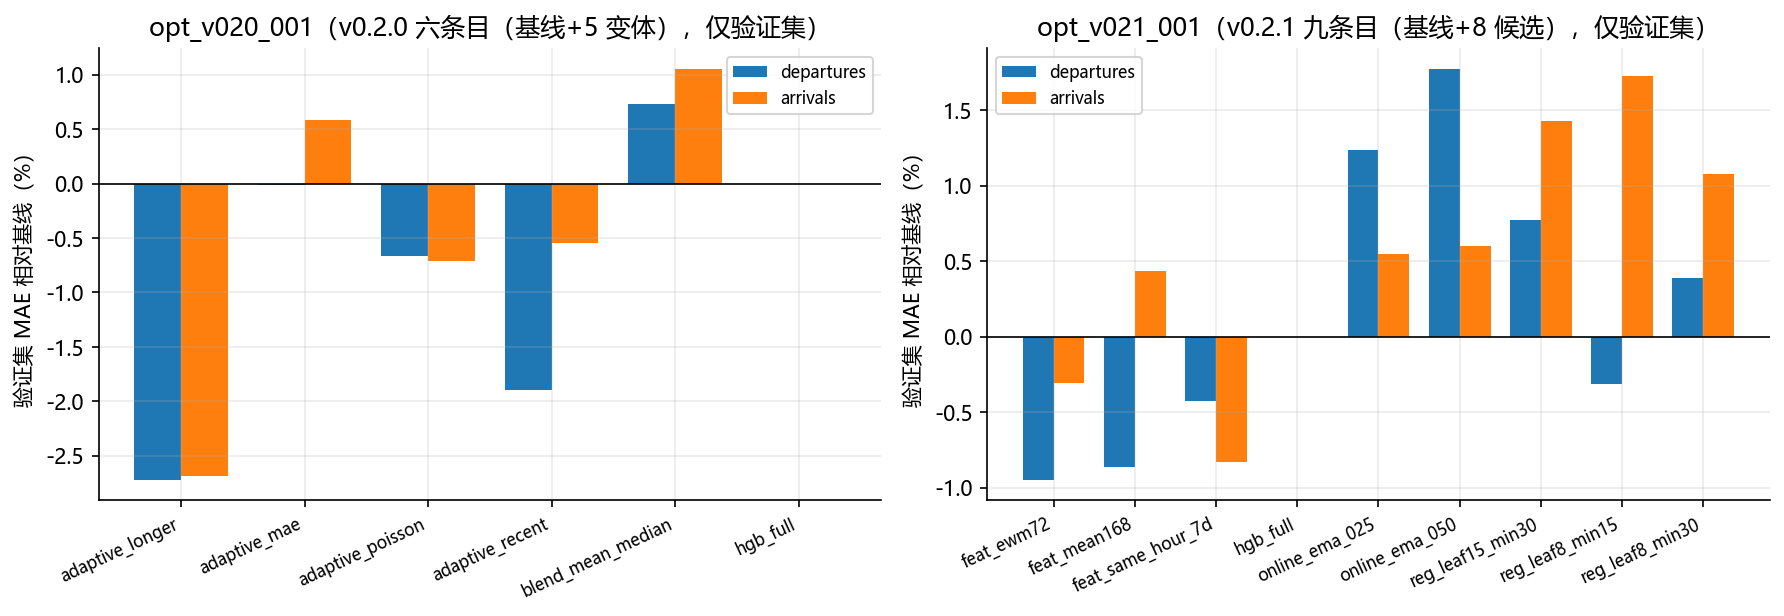

In [14]:
tables = core.candidate_tables(cfg)
rounds = core.round_summary(cfg, tables)
display(pd.DataFrame(rounds))
for run_id, frame in tables.items():
    print(run_id)
    display(frame["metrics"][["target", "model", "mae", "paired_ci_low", "paired_ci_high"]].round(4))
figures.fig_candidates(tables, cfg, Path("figures"))
display(Image(filename="figures/fig10_candidate_validation.png"))

In [15]:
for run_id, frame in tables.items():
    decisions = frame["decisions"]
    eligible = decisions[decisions.eligible == True]
    print(run_id, "eligible rows:", len(eligible))
    display(eligible[["target", "model"]])

opt_v020_001 eligible rows: 0


,target,model


opt_v021_001 eligible rows: 1


,target,model
6,arrivals,reg_leaf15_min30


## 8. 调度建议（条件性）

基于站点净流量与潮汐方向给出补车/疏解优先级。没有容量、库存、成本与道路信息，不能换算成缺车量或收益。

In [16]:
dispatch = core.dispatch_table(data, tide, 8)
display(dispatch[["station_id", "station_name", "events", "daily_net", "am_net_per_hour", "pm_net_per_hour", "pattern"]].round(2))
display(dispatch[["station_id", "suggested_action", "missing_info"]])

,station_id,station_name,events,daily_net,am_net_per_hour,pm_net_per_hour,pattern
0,31277,17th & G St NW,1564,-86.0,-5.23,2.70,早高峰净流入、晚高峰净流出
1,31242,18th St & Pennsylvania Ave NW,1210,-76.0,-4.21,3.34,早高峰净流入、晚高峰净流出
2,31233,17th & K St NW / Farragut Square,1803,-175.0,-4.78,2.21,早高峰净流入、晚高峰净流出
3,31205,21st & I St NW,1864,-84.0,-3.78,1.92,早高峰净流入、晚高峰净流出
4,31279,19th & G St NW,1091,-5.0,-3.59,2.43,早高峰净流入、晚高峰净流出
5,31623,Columbus Circle / Union Station,5955,41.0,-2.51,2.25,早高峰净流入、晚高峰净流出
6,31254,15th & K St NW,1049,-39.0,-3.51,1.86,早高峰净流入、晚高峰净流出
7,31252,21st St & Pennsylvania Ave NW,965,-15.0,-3.25,2.07,早高峰净流入、晚高峰净流出


,station_id,suggested_action,missing_info
0,31277,早间优先疏解；晚间优先补车,站点容量、实时库存、调度车容量与成本、道路可达性均未提供
1,31242,早间优先疏解；晚间优先补车,站点容量、实时库存、调度车容量与成本、道路可达性均未提供
2,31233,早间优先疏解；晚间优先补车,站点容量、实时库存、调度车容量与成本、道路可达性均未提供
3,31205,早间优先疏解；晚间优先补车,站点容量、实时库存、调度车容量与成本、道路可达性均未提供
4,31279,早间优先疏解；晚间优先补车,站点容量、实时库存、调度车容量与成本、道路可达性均未提供
5,31623,早间优先疏解；晚间优先补车,站点容量、实时库存、调度车容量与成本、道路可达性均未提供
6,31254,早间优先疏解；晚间优先补车,站点容量、实时库存、调度车容量与成本、道路可达性均未提供
7,31252,早间优先疏解；晚间优先补车,站点容量、实时库存、调度车容量与成本、道路可达性均未提供


## 9. 局限

覆盖区间全部为 assumed；15.6% 的骑行没有起点站；单月数据；验证 6 天、测试 7 天；测试期已经被查看过；候选没有测试成绩。

In [17]:
limits = pd.DataFrame(data.cleaning["assumptions"], columns=["assumptions"])
display(limits)
coverage = data.coverage
print("coverage rows:", len(coverage), "assumed:", int((coverage.status == "assumed").sum()))
print("no station at start:", int(data.rides.start_station_id.isna().sum()))
print("no station at end:", int(data.rides.end_station_id.isna().sum()))

,assumptions
0,The raw file is the complete set of trips that...
1,A station that shows activity on a day was ope...
2,"A silence at a station is unobserved coverage,..."
3,Endpoint coordinates within 200 m of the stati...
4,The 25-hour duration cap is a provider-side tr...


coverage rows: 985 assumed: 985
no station at start: 37125
no station at end: 39629


## 10. 复现

本 Notebook 由 `scripts/export_all.py` 生成并执行；HTML 是这份已执行 Notebook 的直接导出。
重跑命令见包内 `运行说明.md`。